# exp12: Seleksi Gabungan dan Model Akhir

Mengevaluasi pemilihan pipeline dari 154 kandidat terdaftar menggunakan nested evaluation. Pilihan tiap outer fold hanya memakai inner validation. Setelah evaluasi, konfigurasi refit dipilih melalui group validation seluruh data; model final bukan sumber skor generalisasi tambahan.

Dataset: good_acceptable, window 15 detik, langkah 5 detik. Target dibaca langsung dari cognitive_load_label (Low=0, Medium=1, High=2), termasuk Low pada fase nonpengerjaan yang sudah diberi label dalam dataset v2. Identitas, konteks CodeArrange, dan kualitas hanya menjadi metadata/pembagi evaluasi, bukan fitur prediksi.

### Konfigurasi

Memakai runtime lokal yang sudah diverifikasi terhadap artefak batch-01 lama. Run ini mengevaluasi seluruh peserta dengan seed 42 dan 300 tree/iterasi untuk model berbasis pohon. Checkpoint yang cocok dilanjutkan; hasil dengan identitas data, kode, atau environment berbeda tidak dicampur.

In [1]:
from pathlib import Path
import json
import sys

location = Path.cwd().resolve()
BATCH = next(p for p in (location, *location.parents) if (p / "shared" / "design_registry.json").is_file())
sys.path.insert(0, str(BATCH))

import pandas as pd
from IPython.display import display, Image
from shared import data, design
from shared.runner import Config, run

EXPERIMENT = "exp12"
WINDOW = "window_15s_step_5s"
DATASET_PATH = data.ROOT / "analysis_sessions" / "dataset_fusion" / "output" / "v2_session_phase" / WINDOW / "good_acceptable.csv"
config = Config(dataset_path=DATASET_PATH, output_root=BATCH / "outputs", experiment=EXPERIMENT)
print(DATASET_PATH)

D:\Penelitian Pak Hadi\Adaptive-IDE\analysis_sessions\dataset_fusion\output\v2_session_phase\window_15s_step_5s\good_acceptable.csv


### Dataset dan Kandidat

Memeriksa label, ID window, timestamp, dan allowlist sensor sebelum training. Tidak ada pemetaan ulang dari difficulty. Missing value dan fitur konstan ditangani pada training masing-masing fold, bukan secara global.

In [2]:
frame = data.load_dataset(DATASET_PATH)
display(pd.DataFrame(data.describe_data(frame)["class_counts"].items(), columns=["label", "windows"]))
specifications = design.registry(EXPERIMENT)
display(pd.DataFrame([{**{k: v for k, v in item.items() if k != "candidates"}, "candidate_count": len(item["candidates"])} for item in specifications]))
print(f"{len(frame)} windows; {frame.participant_id.nunique()} participants; {len(data.FEATURES)} base sensor features")

,label,windows
0,Low,732
1,Medium,1105
2,High,1174


,id,model,scaler,tune,variant,candidate_count
0,nested_selection,selection,standard,True,clean,154


3011 windows; 13 participants; 26 base sensor features


### Fold dan Training

Leave-one-participant-out menghasilkan satu prediksi test untuk setiap window. Tiga inner group fold, bila diperlukan tuning, hanya menggunakan peserta training. Kriteria seleksi adalah macro-F1 gabungan prediksi inner; parameter terpilih lalu dilatih ulang pada seluruh outer training. Imputasi, scaler, feature selection, dan resampling tidak melihat outer test.

Cache menyimpan hasil fit/prediksi dengan hash data, urutan ID split, pipeline, parameter, seed, kode, dan paket. Hash output diperiksa sebelum melanjutkan checkpoint.

In [3]:
folds = data.make_folds(frame)
display(pd.DataFrame([{"fold": f["fold_id"], "test_participant": f["participant_id"], "train_windows": len(f["train"]), "test_windows": len(f["test"]), "inner_folds": len(f["inner"])} for f in folds]))
RESULT_DIR = run(config)
print(RESULT_DIR)

,fold,test_participant,train_windows,test_windows,inner_folds
0,fold_00,Andrean,2698,313,3
1,fold_01,Andreas,2825,186,3
2,fold_02,Athaya,2755,256,3
3,fold_03,Fabian,2708,303,3
4,fold_04,Rafi,2691,320,3
5,fold_05,Savitri,2724,287,3
6,fold_06,Shakilla,2897,114,3
7,fold_07,Tio,2741,270,3
8,fold_08,faqih,2718,293,3
9,fold_09,ikhsan,2792,219,3


Complete run verified: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp12\window_15s_step_5s\full_283101608709


D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp12\window_15s_step_5s\full_283101608709


### Evaluasi

Macro-F1 pooled pada tiga kelas menjadi metrik utama. Accuracy, balanced accuracy, precision/recall/F1 per kelas, dan variasi antarorang melengkapi penilaian. Kelas tanpa contoh pada test seseorang tetap kosong pada laporan kelas, bukan dianggap performa nol.

In [4]:
metrics = pd.read_csv(RESULT_DIR / "metrics.csv").sort_values("macro_f1", ascending=False)
display(metrics)
classes = pd.read_csv(RESULT_DIR / "class_metrics.csv")
display(classes[classes.scope.eq("pooled")].drop(columns=["participant_id"], errors="ignore"))
display(pd.read_csv(RESULT_DIR / "participant_summary.csv", header=[0, 1], index_col=0))

,model,accuracy,balanced_accuracy,macro_f1,windows
0,nested_selection,0.313517,0.322499,0.313573,3011


,scope,model,label,precision,recall,f1,support
0,pooled,nested_selection,Low,0.264186,0.387978,0.314333,732
1,pooled,nested_selection,Medium,0.337125,0.295023,0.314672,1105
2,pooled,nested_selection,High,0.344685,0.284497,0.311713,1174


accuracy                    balanced_accuracy            \
                      min   median       max               min    median   
model                                                                      
nested_selection  0.04386  0.28754  0.447099           0.15625  0.333333   

                            macro_f1                      
                       max       min    median       max  
model                                                     
nested_selection  0.465689  0.079814  0.243734  0.451064

### Confusion Matrix

Baris adalah label referensi, kolom adalah prediksi. Diagonal menunjukkan recall kelas pada gambar ternormalisasi. Maksimal enam model ditampilkan di notebook; seluruh confusion matrix tersimpan pada direktori hasil.

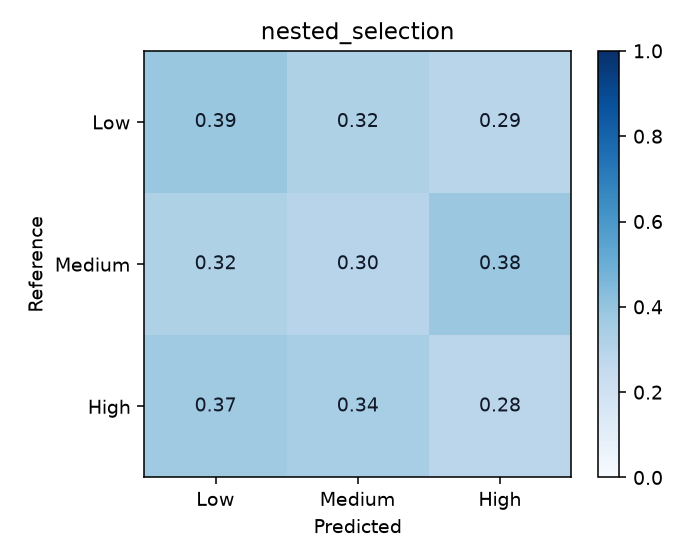

In [5]:
for name in metrics.model.head(6):
    display(Image(filename=str(RESULT_DIR / "figures" / f"{name}_normalized.png")))

### Ketahanan dan Refit

Seed 17/2026 mengulang fit pipeline yang dipilih pada seed utama, bukan mencari seed test terbaik. Bootstrap 1.000 kali mengambil sampel peserta, bukan window independen. Subset nonoverlap dan kualitas memakai prediksi OOF yang sama. Learning curve memakai model referensi pada 3/6/9/12 orang training. Model final dipilih melalui group validation seluruh data dan diuji kesamaan prediksinya setelah save/load.

In [6]:
for filename in ["seed_sensitivity.csv", "quality_metrics.csv", "learning_curve.csv"]:
    print(filename)
    display(pd.read_csv(RESULT_DIR / filename))
display(json.loads((RESULT_DIR / "bootstrap_intervals.json").read_text()))
display(json.loads((RESULT_DIR / "final_selection.json").read_text()))

seed_sensitivity.csv


,seed,accuracy,balanced_accuracy,macro_f1,windows
0,17,0.312853,0.321896,0.312909,3011
1,2026,0.315510,0.324475,0.315539,3011


quality_metrics.csv


,quality_tier,accuracy,balanced_accuracy,macro_f1,windows
0,acceptable,0.284036,0.295892,0.285379,1447
1,good,0.340793,0.346348,0.338868,1564


learning_curve.csv


,fold_id,model,training_participants,fraction,status,accuracy,balanced_accuracy,macro_f1,windows
0,fold_00,logistic,3,0.25,complete,0.306709,0.333963,0.261484,313
1,fold_00,xgboost,3,0.25,complete,0.220447,0.289474,0.177916,313
2,fold_00,logistic,6,0.50,complete,0.559105,0.557215,0.511550,313
3,fold_00,xgboost,6,0.50,complete,0.274760,0.347961,0.237794,313
4,fold_00,logistic,9,0.75,complete,0.536741,0.506770,0.419960,313
...,...,...,...,...,...,...,...,...,...
99,fold_12,xgboost,6,0.50,complete,0.500000,0.486772,0.336508,138
100,fold_12,logistic,9,0.75,complete,0.195652,0.170635,0.152736,138
101,fold_12,xgboost,9,0.75,complete,0.115942,0.105159,0.110534,138
102,fold_12,logistic,12,1.00,complete,0.065217,0.070106,0.082437,138


{'accuracy': {'lower': 0.2492396668555154, 'upper': 0.3691810187629113},
 'balanced_accuracy': {'lower': 0.2679402013456538,
  'upper': 0.3680705490227111},
 'macro_f1': {'lower': 0.24559440390974743, 'upper': 0.3609859120716576}}

{'candidate': {'id': 'c156',
  'pipeline': {'model': 'logistic',
   'scaler': 'standard',
   'strategy': 'fusion',
   'variant': 'clean'},
  'settings': {'alpha': 0.75}},
 'pipeline': {'model': 'logistic',
  'scaler': 'standard',
  'strategy': 'fusion',
  'variant': 'clean'},
 'settings': {'alpha': 0.75},
 'inner_macro_f1': 0.3780185143118409,
 'save_load_check': True,
 'note': 'Full-data group-validation selection and refit; not an additional generalization score.'}

### Artefak

Prediksi, manifest, pencarian kandidat, konfigurasi preprocessing, metrik, dan figure tersedia untuk audit. Bobot model dan cache disimpan lokal tetapi tidak masuk Git. Sumber dataset serta arsip old-dataset tidak diubah.

In [7]:
summary = json.loads((RESULT_DIR / "summary.json").read_text())
assert summary["status"] == "complete"
assert summary["evaluated_folds"] == frame.participant_id.nunique()
print(f"Status: {summary['status']}")
print(f"Output: {RESULT_DIR}")

Status: complete
Output: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp12\window_15s_step_5s\full_283101608709


### Contoh Prediksi Model Final

Memuat artefak refit yang tepercaya dan menjalankan prediksi tanpa kolom target. Contoh ini menunjukkan penggunaan model, bukan skor evaluasi tambahan.

In [8]:
from inference import load_model, predict_frame

final_model = load_model(RESULT_DIR / "final_model.joblib")
sample = frame.head(12).drop(columns=["y", "cognitive_load_label"])
if not final_model.spec.get("temporal"):
    sample = sample[data.FEATURES]
display(predict_frame(final_model, sample))

,y_pred,predicted_label,prob_Low,prob_Medium,prob_High
0,2,High,0.316094,0.329476,0.354430
1,0,Low,0.345933,0.320328,0.333739
2,2,High,0.305826,0.325618,0.368557
3,2,High,0.289620,0.323237,0.387143
4,2,High,0.274200,0.323426,0.402374
5,1,Medium,0.282377,0.363907,0.353716
6,1,Medium,0.281280,0.381309,0.337411
7,1,Medium,0.299843,0.368274,0.331884
8,2,High,0.291354,0.346978,0.361668
9,2,High,0.307996,0.327018,0.364986
